# 8) CNNs and transformations on images: MNIST dataset of numbers

In [119]:
import torch
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import MNIST

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from torchvision.transforms import v2                   # TRANSFORM IMAGES: TRANSLATIONS, ROTATIONS, ZOOM

from torchvision.transforms import InterpolationMode    # interpolation method to rotate

In [120]:
class MNISTDataset(Dataset):

    def __init__(self, do_augmentation=False):

        data = MNIST('mnist', download=True)
        self.images, self.labels = data.data, data.targets

        self.do_augmentation = do_augmentation
        self.translation = v2.RandomCrop(size=28, padding=4, fill=0)
        self.rotation = v2.RandomRotation(degrees=10, fill=0, interpolation=InterpolationMode.BILINEAR)
        self.zoom = v2.RandomResizedCrop(size=(28, 28), scale=[0.8, 1.2], antialias=True)

    def __len__(self):

        return len(self.images)

    def __getitem__(self, idx: int):        # return element of index i

        image = self.images[idx].float() / 255.0
        label = self.labels[idx]

        if self.do_augmentation:
            image = self.translation(image.view(1, 28, 28))
            image = self.rotation(image)
            image = self.zoom(image)
        
        return image[0], label


In [121]:
dataset = MNISTDataset(do_augmentation=True)

idx_train, idx_valid = train_test_split(range(len(dataset)), test_size=0.1, random_state=0)
train_dataset = Subset(dataset, idx_train)
valid_dataset = Subset(dataset, idx_valid)

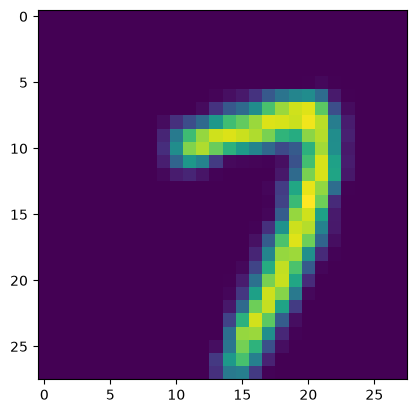

In [122]:
plt.imshow(train_dataset[0][0])

In [123]:

def collate_fn(batch):
    # batch : une liste de longueur 32 = batch_size, avec batch[0] = premiere_image, premiere_etiquette, etc.
    images = []
    labels = []
    for image, label in batch:
        images.append(image)
        labels.append(label)
    # Deux listes : images et labels, chacune de longueur 32 de éléments : torch.Tensor
    # stack "empile" les 32 tenseurs dans la dimension 0
    images = torch.stack(images, dim=0)  # taille : (32, 784)
    labels = torch.tensor(labels)  # taille : (32,)
    return images, labels

train_dataloader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    drop_last=True,
    collate_fn=collate_fn
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size=32,
    # Avec shuffle=False, on a les éléments de validation
    # toujours dans le même ordre ; cela ne change pas l'accuracy,
    # mais c'est utile par exemple si on veut toujours visualiser
    # les premiers points de validation, etc.
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn,
    drop_last=False
)

In [ ]:

class TorchMLP(torch.nn.Module):
    def __init__(self, input_dim, hidden_dims, num_classes):
        super().__init__()

        all_dims = [input_dim] + list(hidden_dims) + [num_classes]

        layers = []
        for dim1, dim2 in zip(all_dims[:-1], all_dims[1:]):
            layers.append(torch.nn.Linear(dim1, dim2))
            layers.append(torch.nn.ReLU())

        # Il ne faut pas mettre de ReLU à la fin !
        layers = layers[:-1]

        # nn.Sequential crée un modèle qui appelle toutes
        # les couches l'une après l'autre.
        self.model = torch.nn.Sequential(*layers)

    def forward(self, x):
        #x = x.reshape(x.size(0), -1)               WHY
        return self.model(x)


modele = TorchMLP(784, [100, 200, 100], 10)#.cuda()
loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(modele.parameters(), lr=0.1)

In [127]:
for epoch in range(10):
    # Tout le tour du jeu d'entraînement
    for images, labels in train_dataloader:
        optimizer.zero_grad()
        y_pred = modele(images)#.to('cuda'))
        loss_result = loss_function(y_pred, labels)#.to('cuda'))
        loss_result.backward()
        optimizer.step()
    # On fait la prévision sur le jeu de validation
    # et on sauvegarde les résultats
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in valid_dataloader:
            logits = modele(images)#.to('cuda'))
            all_preds.extend(torch.argmax(logits, dim=1).to('cpu'))
            all_labels.extend(labels)
    print(accuracy_score(all_labels, all_preds))

0.4806666666666667
0.6908333333333333
0.8233333333333334


KeyboardInterrupt: 